# Telco Customer Churn: End-to-End Classification

This notebook explores the supplied customer data, trains leakage-safe classification pipelines, evaluates churn detection, and exports the selected model for inference.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
    PrecisionRecallDisplay, RocCurveDisplay,
)
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedKFold, cross_val_score, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
DATA_PATH = Path('WA_Fn-UseC_-Telco-Customer-Churn.csv')
ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Place the supplied CSV beside this notebook: {DATA_PATH.resolve()}')

## 1. Load and explore
`TotalCharges` is stored as text in the source and contains blank strings. Convert it to numeric now; the imputer itself is fitted later on training folds only.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head())
display(df.dtypes.rename('dtype').to_frame())
display(df.isna().sum().sort_values(ascending=False).rename('missing').to_frame().head(10))

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Blank/unparseable TotalCharges after conversion: {df['TotalCharges'].isna().sum()}")
print('Duplicate rows:', df.duplicated().sum())
display(df.describe(include='all').T)

Shape: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Blank/unparseable TotalCharges after conversion: 11
Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,share
Churn,,
No,5174,0.7346
Yes,1869,0.2654


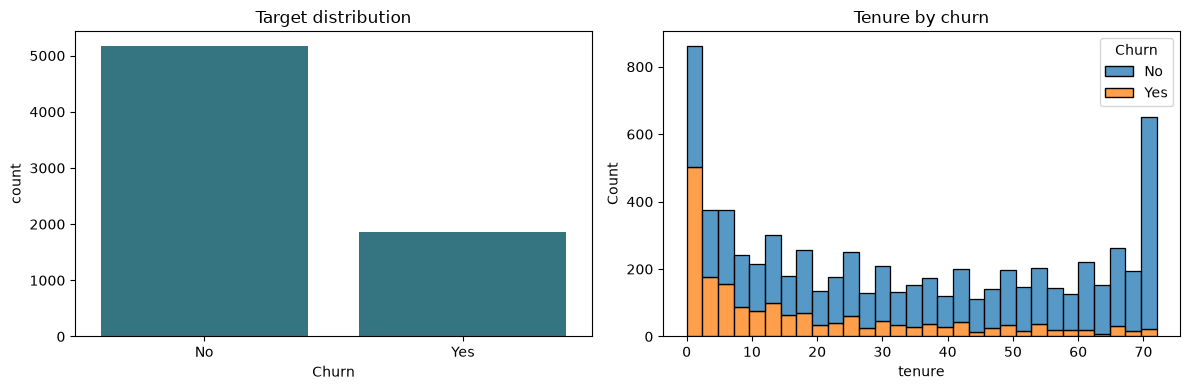

Churn prevalence: 26.5%


In [3]:
target_counts = df['Churn'].value_counts()
display(pd.DataFrame({'count': target_counts, 'share': (target_counts / len(df)).round(4)}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Churn', ax=axes[0], color='#287D8E')
axes[0].set_title('Target distribution')
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack', ax=axes[1])
axes[1].set_title('Tenure by churn')
plt.tight_layout()
plt.show()
print(f"Churn prevalence: {(df['Churn'].eq('Yes').mean()):.1%}")

## 2. Split and preprocess
`customerID` is an identifier, not a predictive feature, so it is excluded. The stratified test split preserves churn prevalence. Imputation, scaling, and one-hot encoding live inside each model pipeline, preventing information from validation/test folds from leaking into preprocessing. Class weights account for the minority churn class.

In [4]:
X = df.drop(columns=['Churn', 'customerID'])
y = df['Churn'].map({'No': 0, 'Yes': 1})
if y.isna().any():
    raise ValueError('Unexpected target labels; expected Churn values Yes/No.')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
numeric_features = X_train.select_dtypes(include='number').columns.tolist()
categorical_features = X_train.select_dtypes(exclude='number').columns.tolist()
print('Numeric:', numeric_features)
print('Categorical:', categorical_features)
print(f'Train rows: {len(X_train):,}; test rows: {len(X_test):,}')
print(f'Train churn rate: {y_train.mean():.1%}; test churn rate: {y_test.mean():.1%}')

numeric_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
categorical_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_preprocessing, numeric_features),
    ('categorical', categorical_preprocessing, categorical_features),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Train rows: 5,634; test rows: 1,409
Train churn rate: 26.5%; test churn rate: 26.5%


## 3. Baseline: logistic regression
Five-fold stratified CV is run on the training partition only. ROC-AUC is the tuning objective because it evaluates ranking across thresholds; average precision is also reported to reflect minority-class retrieval.

In [5]:
logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
])
logistic_cv_auc = cross_val_score(
    logistic_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1
)
print(f'Logistic regression CV ROC-AUC: {logistic_cv_auc.mean():.4f} +/- {logistic_cv_auc.std():.4f}')

Logistic regression CV ROC-AUC: 0.8459 +/- 0.0124


## 4. Tuned ensemble: random forest
Randomized search is restricted to training folds. The modest search budget keeps this notebook practical while testing tree depth, feature subsampling, leaf size, and class weighting.

In [6]:
forest_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
param_distributions = {
    'classifier__n_estimators': [150, 250, 350],
    'classifier__max_depth': [None, 8, 12, 18],
    'classifier__min_samples_leaf': [1, 2, 4, 8],
    'classifier__max_features': ['sqrt', 0.7],
    'classifier__class_weight': ['balanced', 'balanced_subsample'],
}
search = RandomizedSearchCV(
    forest_pipeline, param_distributions=param_distributions, n_iter=10,
    scoring='roc_auc', cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
    refit=True, verbose=1,
)
search.fit(X_train, y_train)
print('Best CV ROC-AUC:', round(search.best_score_, 4))
print('Best parameters:', search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV ROC-AUC: 0.8467
Best parameters: {'classifier__n_estimators': 150, 'classifier__min_samples_leaf': 8, 'classifier__max_features': 0.7, 'classifier__max_depth': 8, 'classifier__class_weight': 'balanced'}


## 5. Holdout evaluation
Accuracy is insufficient here: a model that predicts the majority 'No churn' class can look acceptable while missing many customers who churn. ROC-AUC measures ranking, average precision summarizes the precision-recall curve for the minority class, and precision/recall/F1 show performance at the chosen 0.5 threshold. The held-out test set is used only after model selection.

,roc_auc,average_precision,precision,recall,f1
model,,,,,
Logistic regression,0.8413,0.6326,0.5043,0.7834,0.6136
Tuned random forest,0.8423,0.6507,0.5339,0.7781,0.6333


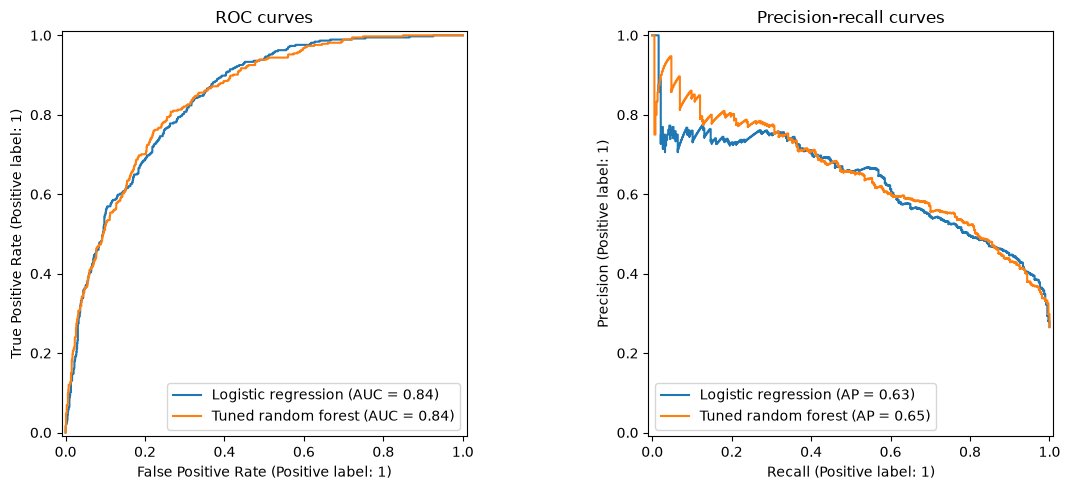


Logistic regression - confusion matrix [true 0/1 rows, predicted 0/1 columns]:
[[747 288]
 [ 81 293]]
              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Tuned random forest - confusion matrix [true 0/1 rows, predicted 0/1 columns]:
[[781 254]
 [ 83 291]]
              precision    recall  f1-score   support

    No churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [7]:
models = {
    'Logistic regression': logistic_pipeline.fit(X_train, y_train),
    'Tuned random forest': search.best_estimator_,
}

def evaluate_model(name, model):
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    return {
        'model': name,
        'roc_auc': roc_auc_score(y_test, probabilities),
        'average_precision': average_precision_score(y_test, probabilities),
        'precision': precision_score(y_test, predictions, zero_division=0),
        'recall': recall_score(y_test, predictions, zero_division=0),
        'f1': f1_score(y_test, predictions, zero_division=0),
    }

results = pd.DataFrame([evaluate_model(name, model) for name, model in models.items()]).set_index('model')
display(results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=name)
axes[0].set_title('ROC curves')
axes[1].set_title('Precision-recall curves')
plt.tight_layout()
plt.show()

for name, model in models.items():
    print(f'\n{name} - confusion matrix [true 0/1 rows, predicted 0/1 columns]:')
    print(confusion_matrix(y_test, model.predict(X_test)))
    print(classification_report(y_test, model.predict(X_test), target_names=['No churn', 'Churn'], zero_division=0))

## 6. Select and export
Choose between the two candidates using training-only cross-validation ROC-AUC; the test metrics remain an unbiased final comparison. The complete preprocessing-plus-classifier pipeline is serialized so inference receives raw customer fields.

In [8]:
selected_name = 'Tuned random forest' if search.best_score_ >= logistic_cv_auc.mean() else 'Logistic regression'
selected_model = models[selected_name]
artifact_path = ARTIFACT_DIR / 'telco_churn_model.joblib'
joblib.dump(selected_model, artifact_path)
print(f'Selected by CV ROC-AUC: {selected_name}')
print(f'Saved complete inference pipeline to: {artifact_path.resolve()}')

Selected by CV ROC-AUC: Tuned random forest
Saved complete inference pipeline to: C:\Users\RUSHIKESH\Desktop\Telco Customer Churn\artifacts\telco_churn_model.joblib


## 7. Single-customer inference example
The sample matches the supplied customer profile. The identifier is accepted at the interface but intentionally removed before prediction.

In [9]:
sample_customer = {
    'customerID': '7590-VHVEG', 'gender': 'Female', 'SeniorCitizen': 0,
    'Partner': 'Yes', 'Dependents': 'No', 'tenure': 1, 'PhoneService': 'No',
    'MultipleLines': 'No phone service', 'InternetService': 'DSL',
    'OnlineSecurity': 'No', 'OnlineBackup': 'Yes', 'DeviceProtection': 'No',
    'TechSupport': 'No', 'StreamingTV': 'No', 'StreamingMovies': 'No',
    'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check', 'MonthlyCharges': 29.85,
    'TotalCharges': '29.85',
}

def predict_customer(payload, model=selected_model):
    customer = dict(payload)
    customer.pop('customerID', None)
    customer['TotalCharges'] = pd.to_numeric(customer.get('TotalCharges'), errors='coerce')
    probability = float(model.predict_proba(pd.DataFrame([customer]))[0, 1])
    prediction = int(probability >= 0.5)
    return {'prediction': prediction, 'churn_label': 'Yes' if prediction else 'No', 'churn_probability': probability}

print(json.dumps(predict_customer(sample_customer), indent=2))

{
  "prediction": 1,
  "churn_label": "Yes",
  "churn_probability": 0.7755754521932963
}


In [10]:
import subprocess
import sys

completed = subprocess.run(
    [sys.executable, 'predict.py', json.dumps(sample_customer)],
    check=True, capture_output=True, text=True,
)
cli_result = json.loads(completed.stdout)
assert cli_result['prediction'] in (0, 1)
assert 0.0 <= cli_result['churn_probability'] <= 1.0
print('CLI smoke test:', cli_result)

CLI smoke test: {'prediction': 1, 'churn_label': 'Yes', 'churn_probability': 0.7755754521932963}


## 8. Next improvements
1. Add temporal or repeatable data validation and drift monitoring, with model/data versioning and a retraining trigger.
2. Calibrate probabilities and select a decision threshold from retention costs/capacity; evaluate subgroup performance and fairness.
3. Package the inference contract with schema validation, automated tests, CI, and a versioned serving container/API with logging and latency monitoring.